# Indoor PM2.5 Prediction

This notebook predicts indoor PM2.5 concentrations using the LBNL California homes dataset.

**Why this approach:** Indoor PM2.5 is influenced by outdoor pollution, ventilation, and occupant behavior. Machine learning allows us to capture these relationships and evaluate generalization to new homes.

## 1. Setup and Configuration

All default settings are stored in `config.py` so they can be changed in one place.

**Key defaults:**
- 10-minute resolution
- Household-level train/test split
- Medium feature set (~20 features)
- 200 trees for gradient boosting models

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import lightgbm as lgb
import xgboost as xgb

from pipeline import load_and_prepare
from config import *

sns.set_style("whitegrid")
print("Configuration loaded")
print(f"Feature level : {DEFAULT_FEATURE_LEVEL}")
print(f"Split type    : {DEFAULT_SPLIT}")
print(f"n_estimators  : {DEFAULT_N_ESTIMATORS}")



Configuration loaded
Feature level : medium
Split type    : household
n_estimators  : 200


## 2. Data Loading, Preprocessing, and Exploratory Analysis

### 2.1 Data Loading
Household sensor files are loaded from multiple folders. Files ending with household IDs (e.g., `Qtotal001.csv`) are identified and combined. macOS metadata files are skipped.

### 2.2 Preprocessing Steps
1. **Timestamp standardization** – Time columns are renamed to `timestamp` and converted to datetime.
2. **Resampling** – Minute-level data is aggregated to 10-minute averages to reduce noise while preserving short-term patterns.
3. **Outlier capping** – Indoor PM2.5 values above 100 µg/m³ are capped. Extreme spikes were rare and distorted error metrics.
4. **Lag features** – Recent past values of indoor PM, outdoor PM, and ventilation metrics are created (lag1, lag3, lag6, etc.).
5. **Time features** – Hour, day of week, weekend flag, and month are added.
6. **Household mean** – Each home’s average indoor PM (calculated from training data only) is added as a feature.
7. **Feature reduction** – Sparse or room-specific columns are removed. Only high-value features are kept.
8. **Missing value handling** – Completely empty columns are dropped. Remaining missing values are filled with the median.

### 2.3 Why These Steps
- **10-minute resolution** improves short-term prediction compared to hourly averages.
- **Capping** stabilizes training without removing real high-pollution events.
- **Lags** capture the strong temporal dependence of indoor PM.
- **Household mean** accounts for systematic differences between homes.
- **Feature reduction** improves interpretability and reduces overfitting risk.
- **Median imputation** is robust to outliers.

### 2.4 Train/Test Split
Data is split by **household** so the model is evaluated on homes it has never seen. This tests generalization to new buildings.

In [3]:
# Load and prepare data using the shared pipeline
X_train, y_train, X_test, y_test, feature_cols, train, test = load_and_prepare(
    freq="10min",
    feature_level=DEFAULT_FEATURE_LEVEL,
    split_type=DEFAULT_SPLIT
)

print(f"\nFinal feature count: {len(feature_cols)}")
print("Features:")
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {col}")

print(f"\nTrain households: {train['household_id'].nunique()}")
print(f"Test households:  {test['household_id'].nunique()}")
print(f"Train rows: {len(X_train):,}")
print(f"Test rows:  {len(X_test):,}")

Loading data | freq=10min | features=medium | split=household
Household split: 55 train homes, 13 test homes
Train rows: 50,729 | Test rows: 12,134
Train: 50,729 | Test: 12,134 | Features: 16

Final feature count: 16
Features:
   1. PM_MET_IN1_lag1
   2. PM_MET_OUT
   3. hh_mean_pm
   4. CO2_ETC_IN1
   5. PM_MET_IN1_lag3
   6. QCFM_Exhaust
   7. ACH
   8. hour
   9. PM_MET_IN1_lag6
  10. PM_MET_IN1_lag12
  11. T_ETC_IN1
  12. RH_ETC_IN1
  13. T_ETC_OUT
  14. RH_ETC_OUT
  15. QCFM_Total
  16. ACH_lag1

Train households: 55
Test households:  13
Train rows: 50,729
Test rows:  12,134


### 2.5 Quick EDA Checks

Before modeling, it is useful to inspect:
- Distribution of the target variable
- Missingness in key features
- Correlation of top features with the target

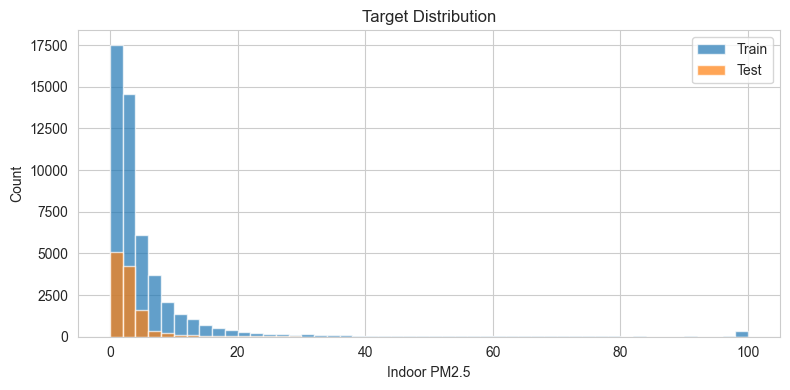

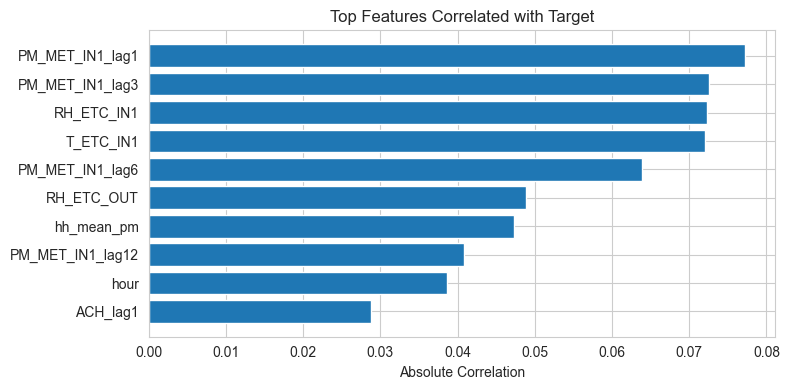


Top correlations with target:
PM_MET_IN1_lag1     0.077
PM_MET_IN1_lag3     0.073
RH_ETC_IN1          0.072
T_ETC_IN1           0.072
PM_MET_IN1_lag6     0.064
RH_ETC_OUT          0.049
hh_mean_pm          0.047
PM_MET_IN1_lag12    0.041
hour                0.039
ACH_lag1            0.029
dtype: float64


In [4]:
# Target distribution
plt.figure(figsize=(8, 4))
plt.hist(y_train, bins=50, alpha=0.7, label="Train")
plt.hist(y_test, bins=50, alpha=0.7, label="Test")
plt.xlabel("Indoor PM2.5")
plt.ylabel("Count")
plt.title("Target Distribution")
plt.legend()
plt.tight_layout()
plt.show()

# Top correlations with target
corr = X_train.corrwith(y_train).abs().sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 4))
plt.barh(corr.index[::-1], corr.values[::-1])
plt.xlabel("Absolute Correlation")
plt.title("Top Features Correlated with Target")
plt.tight_layout()
plt.show()

print("\nTop correlations with target:")
print(corr.round(3))

## 3. Model Training

Four models are trained using the same prepared data:

| Model | Type | Purpose |
|-------|------|---------|
| Linear Regression | Linear | Simple, interpretable baseline |
| Ridge Regression | Linear + L2 regularization | Handles correlated features |
| LightGBM | Gradient boosting | Captures nonlinear relationships |
| XGBoost | Gradient boosting | Alternative boosting implementation |

### Why these models?
- **Linear models** are strong baselines. If they perform well, the relationship is largely linear given the chosen features.
- **Gradient boosting** can model interactions and nonlinear effects if they exist.
- Comparing both families shows whether added complexity is justified.

### Shared settings
- Features come from the reduced set defined in `config.py`
- Household-level split (test homes are unseen)
- Indoor PM capped at 100 µg/m³
- Median imputation for remaining missing values

In [5]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, r2_score

# -------------------------------------------------
# Linear Regression
# -------------------------------------------------
print("Training Linear Regression...")
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
lr.fit(X_train, y_train)

# -------------------------------------------------
# Ridge Regression
# -------------------------------------------------
print("Training Ridge Regression...")
ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=10.0))
])
ridge.fit(X_train, y_train)

# -------------------------------------------------
# LightGBM
# -------------------------------------------------
print("Training LightGBM...")
lgbm = lgb.LGBMRegressor(
    n_estimators=DEFAULT_N_ESTIMATORS,
    learning_rate=DEFAULT_LEARNING_RATE,
    num_leaves=DEFAULT_NUM_LEAVES,
    max_depth=DEFAULT_MAX_DEPTH,
    min_child_samples=30,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=1.0,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1
)
lgbm.fit(X_train, y_train)

# -------------------------------------------------
# XGBoost
# -------------------------------------------------
print("Training XGBoost...")
xgb_model = xgb.XGBRegressor(
    n_estimators=DEFAULT_N_ESTIMATORS,
    learning_rate=DEFAULT_LEARNING_RATE,
    max_depth=DEFAULT_MAX_DEPTH,
    min_child_weight=30,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=1.0,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=0
)
xgb_model.fit(X_train, y_train)

print("\nAll models trained.")

Training Linear Regression...
Training Ridge Regression...
Training LightGBM...
Training XGBoost...

All models trained.


### Baseline Plots
Predicted vs actual and feature importance for the trained models.

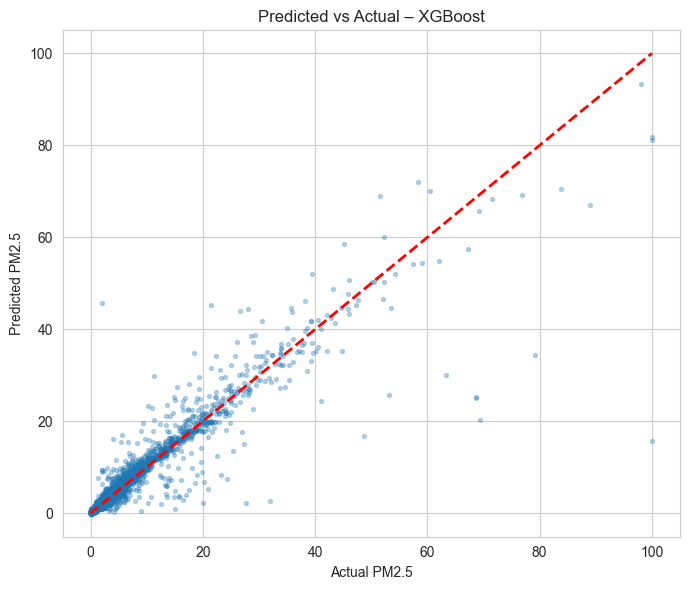

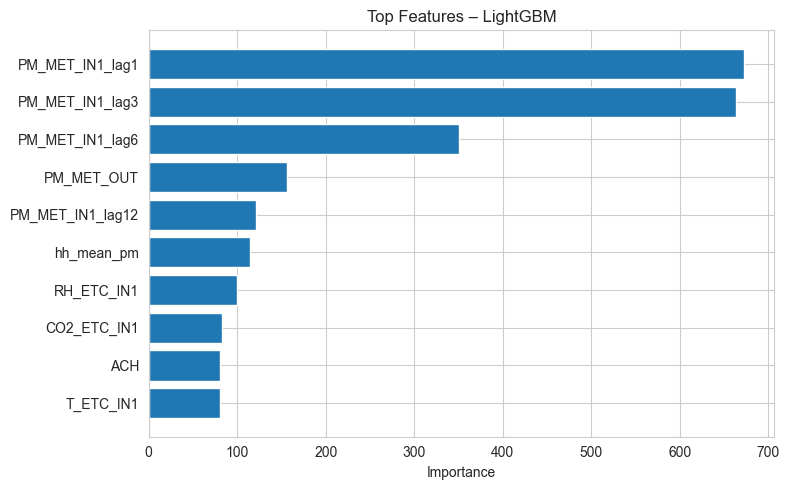

In [6]:
# Predicted vs Actual (example with XGBoost)
y_pred = xgb_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=8)
max_val = max(y_test.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], "r--", lw=2)
plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Predicted vs Actual – XGBoost")
plt.tight_layout()
plt.show()

# Feature importance (LightGBM)
importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False).head(10)

plt.figure(figsize=(8, 5))
plt.barh(importance["feature"][::-1], importance["importance"][::-1])
plt.xlabel("Importance")
plt.title("Top Features – LightGBM")
plt.tight_layout()
plt.show()



### Household-Level Examples

Compare measured vs predicted values for individual households.  
This shows how well the model tracks real patterns in specific homes.

In [7]:
# Use one of the trained models (example: XGBoost)
model = xgb_model
y_pred_test = model.predict(X_test)

# Attach predictions to the test set
test_results = test.copy()
test_results["predicted"] = y_pred_test
test_results["actual"] = y_test.values

# Calculate MAE per household
hh_mae = (
    test_results.groupby("household_id")
    .apply(lambda g: mean_absolute_error(g["actual"], g["predicted"]))
    .sort_values()
)

best_homes = hh_mae.head(2).index.tolist()
worst_homes = hh_mae.tail(2).index.tolist()

print("Best fitting households:", best_homes)
print("Worst fitting households:", worst_homes)

Best fitting households: ['008', '037']
Worst fitting households: ['127', '116']


C:\Users\lifra\AppData\Local\Temp\ipykernel_55468\3576590864.py:13: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: mean_absolute_error(g["actual"], g["predicted"]))


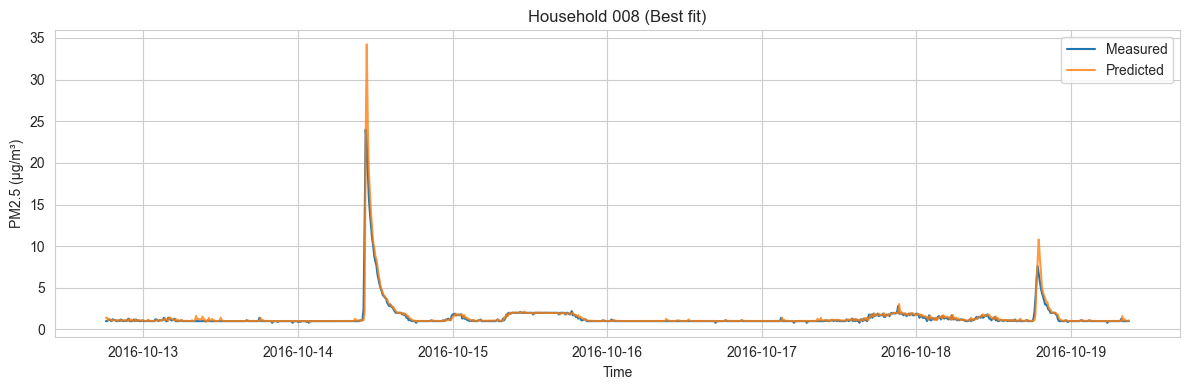

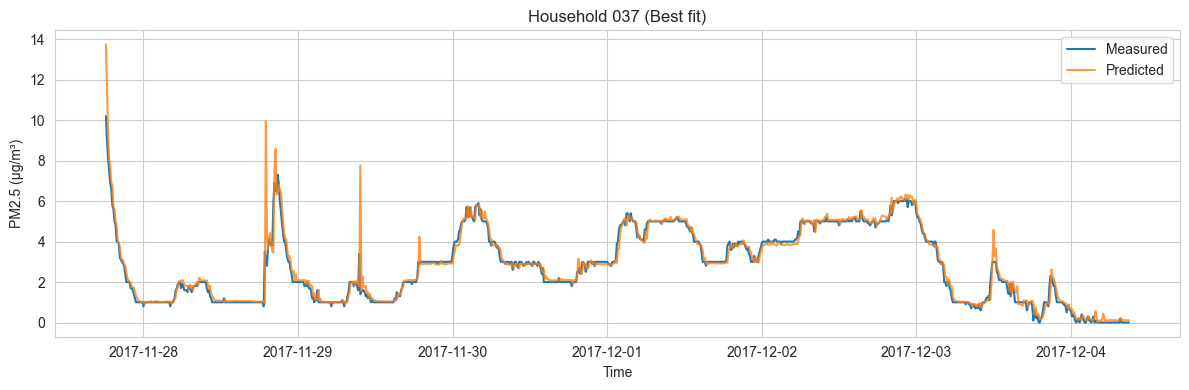

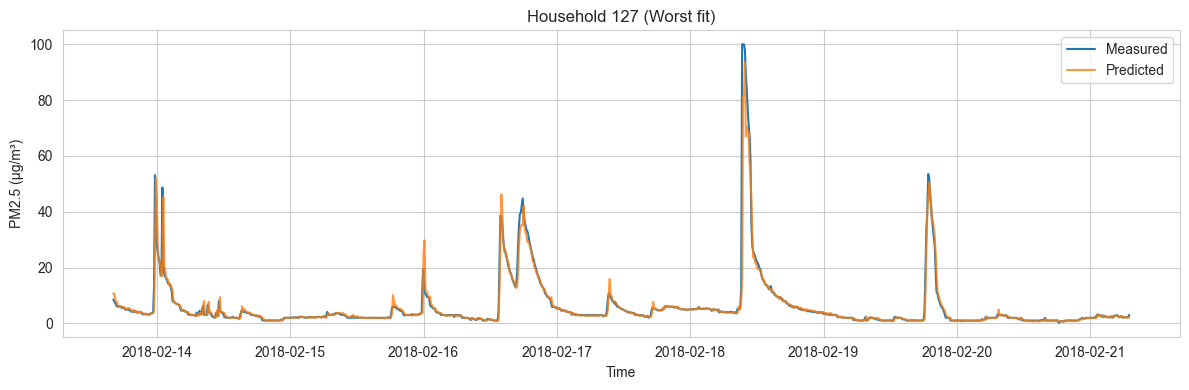

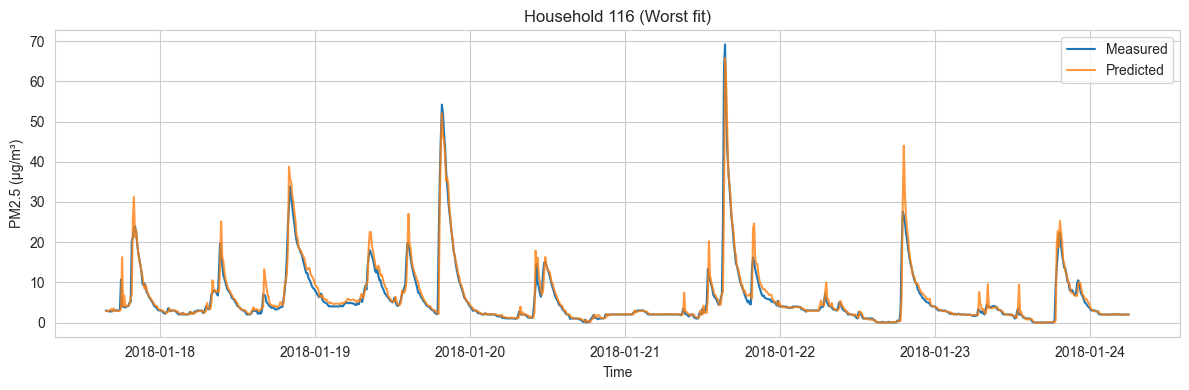

In [8]:
def plot_household(hid, title_suffix=""):
    hh_data = test_results[test_results["household_id"] == hid].sort_values("timestamp")
    plt.figure(figsize=(12, 4))
    plt.plot(hh_data["timestamp"], hh_data["actual"], label="Measured", linewidth=1.5)
    plt.plot(hh_data["timestamp"], hh_data["predicted"], label="Predicted", linewidth=1.5, alpha=0.8)
    plt.title(f"Household {hid} {title_suffix}")
    plt.xlabel("Time")
    plt.ylabel("PM2.5 (µg/m³)")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Best fitting homes
for hid in best_homes:
    plot_household(hid, "(Best fit)")

# Worst fitting homes
for hid in worst_homes:
    plot_household(hid, "(Worst fit)")

### Interpretation

| Household type | What it shows |
|----------------|---------------|
| Best fit | Model closely follows measured PM over time |
| Worst fit | Larger deviations, often due to unusual events, missing sensors, or sparse data |

These plots help assess whether the model captures realistic temporal patterns, not just average error.

### Evaluation Metrics
The models are compared using three metrics:

| Metric | Meaning | Lower is better? |
|--------|---------|------------------|
| MAE | Average absolute error in µg/m³ | Yes |
| RMSE | Penalizes large errors more heavily | Yes |
| MASE | Error relative to a naive “predict previous value” baseline | Yes (and < 1 is good) |

**How to read MASE:**
- MASE < 1 means the model is better than simply using the previous measurement.
- MASE ≈ 1 means the model is no better than the naive baseline.
- MASE > 1 means the model is worse than the naive baseline.

Both training and test performance are reported. A large gap between them can indicate overfitting.

In [14]:
from evaluation import evaluate, compare_models

models = {"Linear": lr, "Ridge": ridge, "LightGBM": lgbm, "XGBoost": xgb_model}
results = compare_models(models, X_train, y_train, X_test, y_test)

=== Model Comparison (Test) ===
Linear           MAE:  0.513   RMSE:  1.795   MASE:  0.840
Ridge            MAE:  0.513   RMSE:  1.795   MASE:  0.840
LightGBM         MAE:  0.497   RMSE:  1.822   MASE:  0.814
XGBoost          MAE:  0.462   RMSE:  1.813   MASE:  0.756


### Interpretation of Results


**Typical observations on this dataset:**
- All models usually achieve MASE < 1, showing they improve on the naive baseline.
- Linear models often perform competitively with gradient boosting when using the reduced feature set.
- A lower MAE/RMSE with a similar MASE suggests the model reduces large errors without sacrificing overall consistency.
- Large differences between train and test performance can indicate overfitting.

These metrics together give a clearer picture than R² alone, especially for time-series prediction where recent values are strong predictors.

## 3.1 Diagnostic Plots

These plots are generated by `plots.py` and help validate key modeling choices.

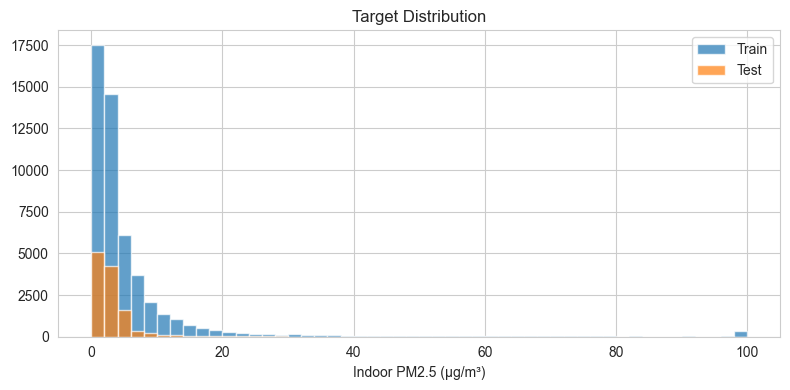

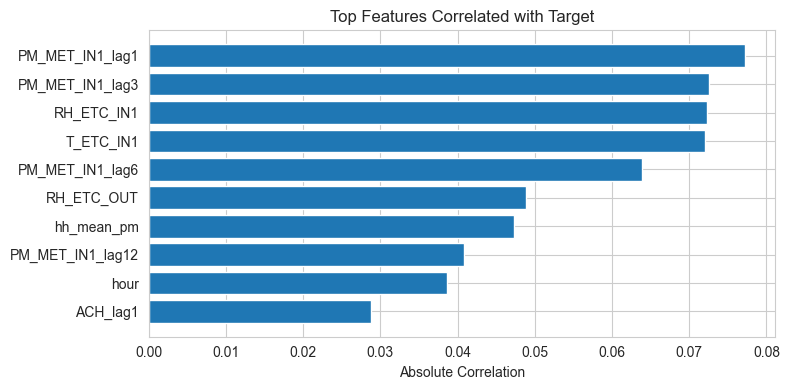

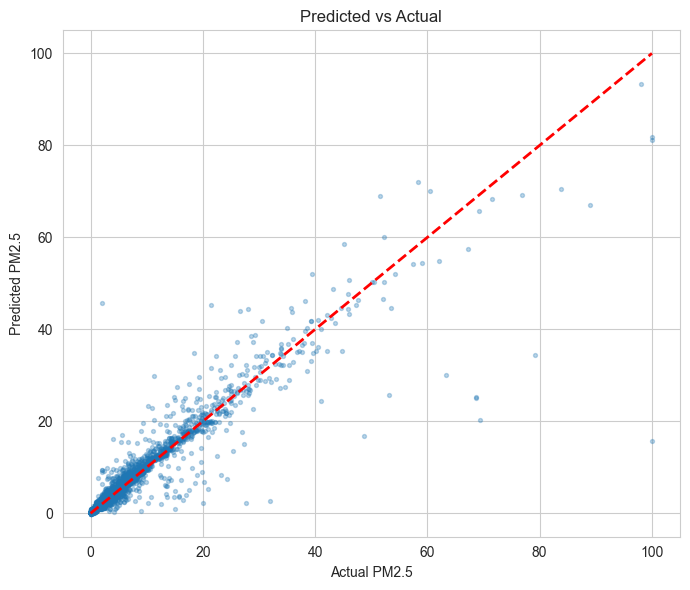

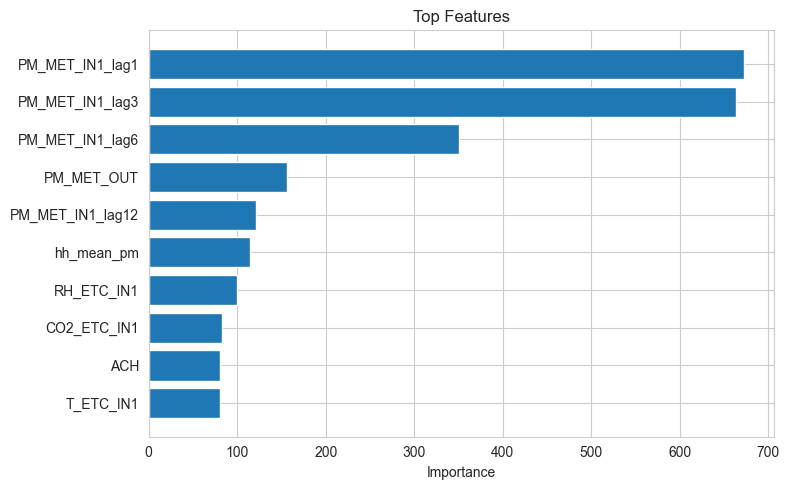

c:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\Project_Final_Cleaned\plots.py:75: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: mean_absolute_error(g["actual"], g["predicted"]))


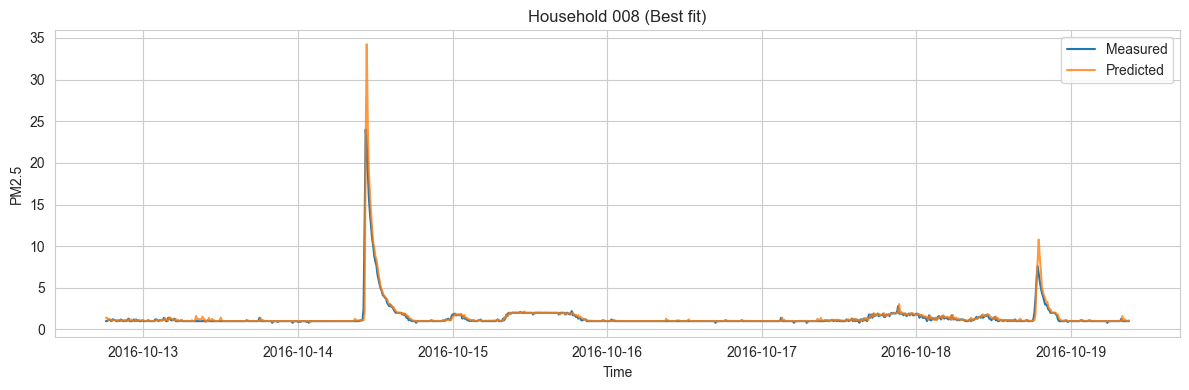

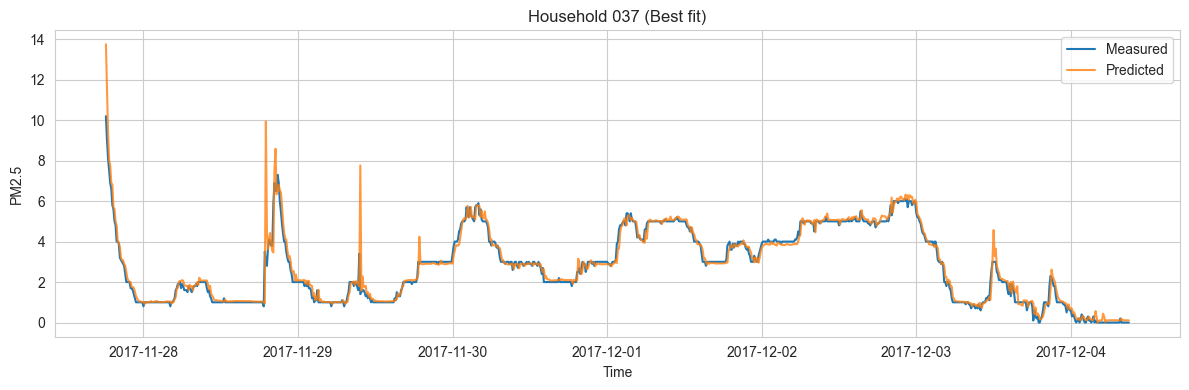

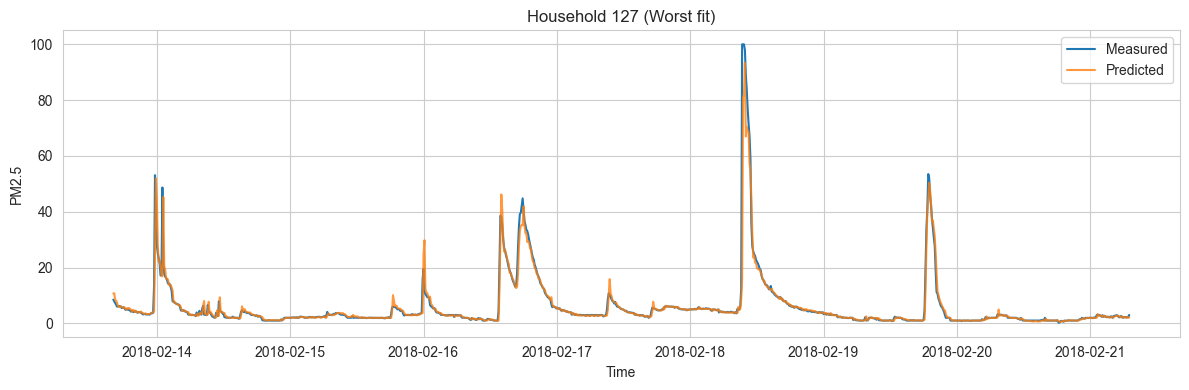

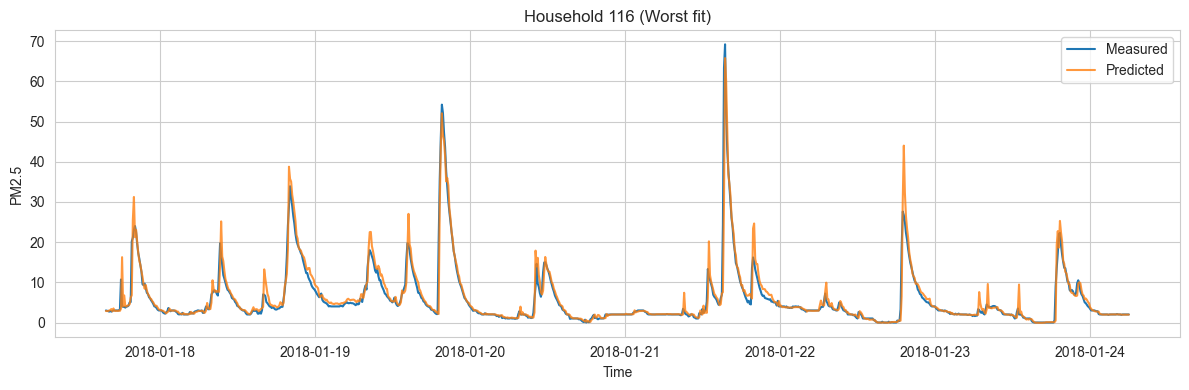

(['008', '037'], ['127', '116'])

In [10]:
from plots import (
    plot_target_distribution, plot_top_correlations,
    plot_pred_vs_actual, plot_feature_importance, plot_household_examples
)

plot_target_distribution(y_train, y_test)
plot_top_correlations(X_train, y_train)
plot_pred_vs_actual(y_test, xgb_model.predict(X_test))
plot_feature_importance(lgbm, feature_cols)
plot_household_examples(test, y_test, xgb_model.predict(X_test))

## 4. Cross-Validation

A single train/test split can be sensitive to which households end up in the test set. Cross-validation provides a more stable estimate of performance.

### Method: GroupKFold by Household

| Aspect | Detail |
|--------|--------|
| Number of folds | 5 (default) |
| Grouping | Each household is kept entirely in one fold |
| What is tested | Completely unseen homes in every fold |
| Purpose | Estimate generalization to new buildings |

### Why GroupKFold?
- A random split could put data from the same home in both train and test, leaking information.
- A time-based split tests future prediction in known homes, which is a different question.
- GroupKFold by household directly answers: “How well does the model work on homes it has never seen?”

### What is reported
For each model:
- Standard deviation (shows stability)

A low standard deviation means performance is consistent across different sets of homes.

In [12]:
from cross_validation import prepare_full_data, run_cv, print_summary

df = prepare_full_data()
results = run_cv(df)
print_summary(results)

Running 5-fold GroupKFold (feature level: medium)

Fold 1: Linear MAE=0.771 | XGB MAE=0.914
Fold 2: Linear MAE=0.623 | XGB MAE=0.677
Fold 3: Linear MAE=0.546 | XGB MAE=0.528
Fold 4: Linear MAE=0.570 | XGB MAE=0.539
Fold 5: Linear MAE=0.731 | XGB MAE=0.755

CROSS-VALIDATION SUMMARY (GroupKFold by Household)

Linear:
  MAE  : 0.648 ± 0.088
  RMSE : 3.099 ± 0.531
  MASE : 1.161 ± 0.214

Ridge:
  MAE  : 0.649 ± 0.088
  RMSE : 3.099 ± 0.531
  MASE : 1.161 ± 0.214

LightGBM:
  MAE  : 0.748 ± 0.147
  RMSE : 3.196 ± 0.565
  MASE : 1.343 ± 0.332

XGBoost:
  MAE  : 0.683 ± 0.144
  RMSE : 3.182 ± 0.591
  MASE : 1.227 ± 0.320


### Interpret the results

| Observation | Meaning |
|-------------|---------|
| Similar mean MAE across models | No clear winner; linear models may be sufficient |
| Low standard deviation | Performance is stable across different homes |
| Higher standard deviation | Some households are harder to predict than others |
| CV MAE close to single-split MAE | The single split was representative |
| CV MAE much higher | The single split was unusually easy |


## 5. Nested Cross-Validation

Nested cross-validation separates hyperparameter tuning from performance evaluation. This gives a less optimistic estimate of real-world performance.

### Structure

| Level | Purpose | Method |
|-------|---------|--------|
| Outer loop | Unbiased performance estimate | GroupKFold by household (5 folds) |
| Inner loop | Hyperparameter tuning | GroupKFold or Optuna inside each outer fold |

### Nested CV validity
- Tuning on the same data used for evaluation can overestimate performance.
- Nested CV keeps the test fold completely untouched during tuning.
- It is more rigorous when reporting final model performance.



In [13]:
from nested_cv import nested_cv

# LightGBM nested CV
lgbm_results = nested_cv(model_type="lightgbm", n_outer=5, n_trials=15)

# XGBoost nested CV
xgb_results = nested_cv(model_type="xgboost", n_outer=5, n_trials=15)


# Uncomment to run (can take a long time)
# nested_scores = nested_cv_lightgbm(df, outer_splits=5, n_trials=15)

Nested CV | Model: lightgbm | Outer folds: 5 | Trials: 15



[I 2026-11-24 12:07:39,085] A new study created in memory with name: no-name-745b46fd-3392-45d2-93eb-396d2192a089
[I 2026-11-24 12:07:39,439] Trial 0 finished with value: 0.5473873594465912 and parameters: {'n_estimators': 134, 'learning_rate': 0.025995143891176464, 'num_leaves': 33, 'max_depth': 6, 'min_child_samples': 49}. Best is trial 0 with value: 0.5473873594465912.
[I 2026-11-24 12:07:39,786] Trial 1 finished with value: 0.49082854083455235 and parameters: {'n_estimators': 334, 'learning_rate': 0.028073154886146225, 'num_leaves': 31, 'max_depth': 5, 'min_child_samples': 37}. Best is trial 1 with value: 0.49082854083455235.
[I 2026-11-24 12:07:40,428] Trial 2 finished with value: 0.42422095310102553 and parameters: {'n_estimators': 430, 'learning_rate': 0.028020879908280862, 'num_leaves': 39, 'max_depth': 7, 'min_child_samples': 19}. Best is trial 2 with value: 0.42422095310102553.
[I 2026-11-24 12:07:40,758] Trial 3 finished with value: 0.48068296438074604 and parameters: {'n_es

Outer fold 1: MAE=0.968  RMSE=4.064  MASE=1.864


[I 2026-11-24 12:07:47,262] Trial 0 finished with value: 0.4015400024051739 and parameters: {'n_estimators': 596, 'learning_rate': 0.08495798558596192, 'num_leaves': 22, 'max_depth': 7, 'min_child_samples': 15}. Best is trial 0 with value: 0.4015400024051739.
[I 2026-11-24 12:07:47,546] Trial 1 finished with value: 0.4446155180560174 and parameters: {'n_estimators': 202, 'learning_rate': 0.08052471665097558, 'num_leaves': 33, 'max_depth': 7, 'min_child_samples': 18}. Best is trial 0 with value: 0.4015400024051739.
[I 2026-11-24 12:07:47,777] Trial 2 finished with value: 0.5328813443099214 and parameters: {'n_estimators': 271, 'learning_rate': 0.03629639610133819, 'num_leaves': 15, 'max_depth': 4, 'min_child_samples': 10}. Best is trial 0 with value: 0.4015400024051739.
[I 2026-11-24 12:07:48,153] Trial 3 finished with value: 0.644429664369309 and parameters: {'n_estimators': 207, 'learning_rate': 0.014758886889726548, 'num_leaves': 41, 'max_depth': 8, 'min_child_samples': 59}. Best is 

Outer fold 2: MAE=0.814  RMSE=3.331  MASE=1.431


[I 2026-11-24 12:07:53,971] Trial 0 finished with value: 0.5376183599079757 and parameters: {'n_estimators': 570, 'learning_rate': 0.02088771717081567, 'num_leaves': 39, 'max_depth': 6, 'min_child_samples': 54}. Best is trial 0 with value: 0.5376183599079757.
[I 2026-11-24 12:07:54,203] Trial 1 finished with value: 0.5354644926610967 and parameters: {'n_estimators': 208, 'learning_rate': 0.0789669875307803, 'num_leaves': 25, 'max_depth': 6, 'min_child_samples': 49}. Best is trial 1 with value: 0.5354644926610967.
[I 2026-11-24 12:07:54,825] Trial 2 finished with value: 0.5434018085025231 and parameters: {'n_estimators': 530, 'learning_rate': 0.017555829354147574, 'num_leaves': 25, 'max_depth': 6, 'min_child_samples': 56}. Best is trial 1 with value: 0.5354644926610967.
[I 2026-11-24 12:07:55,057] Trial 3 finished with value: 0.4436327905114524 and parameters: {'n_estimators': 136, 'learning_rate': 0.09212180216518301, 'num_leaves': 45, 'max_depth': 7, 'min_child_samples': 12}. Best is 

... (11 outputs left out)

[I 2026-11-24 12:08:59,269] Trial 0 finished with value: 0.6460678707624773 and parameters: {'n_estimators': 426, 'learning_rate': 0.010705661872342275, 'max_depth': 3, 'min_child_weight': 21}. Best is trial 0 with value: 0.6460678707624773.
[I 2026-11-24 12:08:59,525] Trial 1 finished with value: 0.5121557180352283 and parameters: {'n_estimators': 245, 'learning_rate': 0.08323467266525006, 'max_depth': 6, 'min_child_weight': 25}. Best is trial 1 with value: 0.5121557180352283.
[I 2026-11-24 12:08:59,998] Trial 2 finished with value: 0.5360559686752763 and parameters: {'n_estimators': 600, 'learning_rate': 0.05035572081212995, 'max_depth': 5, 'min_child_weight': 30}. Best is trial 1 with value: 0.5121557180352283.
[I 2026-11-24 12:09:00,588] Trial 3 finished with value: 0.44368157972379496 and parameters: {'n_estimators': 574, 'learning_rate': 0.030444509237490598, 'max_depth': 6, 'min_child_weight': 6}. Best is trial 3 with value: 0.44368157972379496.
[I 2026-11-24 12:09:00,943] Trial

Outer fold 4: MAE=0.834  RMSE=2.949  MASE=1.418


[I 2026-11-24 12:09:06,545] Trial 0 finished with value: 1.1561331138428963 and parameters: {'n_estimators': 147, 'learning_rate': 0.011769662832944353, 'max_depth': 6, 'min_child_weight': 37}. Best is trial 0 with value: 1.1561331138428963.
[I 2026-11-24 12:09:06,793] Trial 1 finished with value: 0.5542079575622991 and parameters: {'n_estimators': 205, 'learning_rate': 0.018330638588002626, 'max_depth': 6, 'min_child_weight': 28}. Best is trial 1 with value: 0.5542079575622991.
[I 2026-11-24 12:09:07,032] Trial 2 finished with value: 0.48975092642609613 and parameters: {'n_estimators': 253, 'learning_rate': 0.03520089393215034, 'max_depth': 5, 'min_child_weight': 8}. Best is trial 2 with value: 0.48975092642609613.
[I 2026-11-24 12:09:07,543] Trial 3 finished with value: 0.49823552561758166 and parameters: {'n_estimators': 465, 'learning_rate': 0.011444166483061778, 'max_depth': 6, 'min_child_weight': 18}. Best is trial 2 with value: 0.48975092642609613.
[I 2026-11-24 12:09:07,690] Tr

Outer fold 5: MAE=0.708  RMSE=3.755  MASE=1.287

NESTED CV SUMMARY (XGBOOST)
MAE  : 0.847 ± 0.202
RMSE : 3.500 ± 0.648
MASE : 1.522 ± 0.438


### Interpretation
The nested CV score is usually slightly worse than a single tuned model evaluated on one test set. This is expected and more realistic, because the test data was never used during tuning.

## 6. Optimization and Sensitivity Analysis

This section examines how model performance changes with key design choices:
- Number of trees
- Time resolution
- Feature set size
- Hyperparameter tuning

These checks help confirm that the chosen settings are reasonable.

### 6.1 Number of Trees

Gradient boosting models can overfit if too many trees are used. This plot shows test performance as the number of trees increases.

 Trees  Test MAE  Test R²
    50     1.121    0.848
   100     0.514    0.892
   200     0.429    0.888
   400     0.463    0.883
   600     0.477    0.882
   800     0.490    0.880
  1000     0.499    0.879


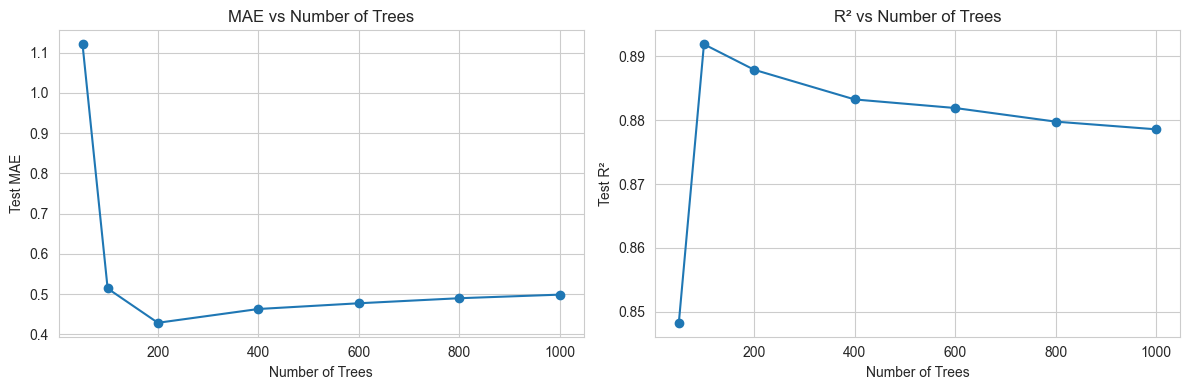

In [8]:
n_trees_list = [50, 100, 200, 400, 600, 800, 1000]
results_trees = []

for n in n_trees_list:
    model = lgb.LGBMRegressor(
        n_estimators=n, learning_rate=0.03, num_leaves=15, max_depth=6,
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results_trees.append({
        "Trees": n,
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R²": r2_score(y_test, pred)
    })

trees_df = pd.DataFrame(results_trees)
print(trees_df.round(3).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(trees_df["Trees"], trees_df["Test MAE"], marker="o")
ax1.set_xlabel("Number of Trees")
ax1.set_ylabel("Test MAE")
ax1.set_title("MAE vs Number of Trees")

ax2.plot(trees_df["Trees"], trees_df["Test R²"], marker="o")
ax2.set_xlabel("Number of Trees")
ax2.set_ylabel("Test R²")
ax2.set_title("R² vs Number of Trees")
plt.tight_layout()
plt.show()

### 6.2 Time Resolution Comparison

Compares model performance when data is aggregated to different time intervals.

Loading data | freq=1h | features=medium | split=household
Household split: 55 train homes, 13 test homes
Train rows: 8,457 | Test rows: 2,022
Train: 8,457 | Test: 2,022 | Features: 16
Loading data | freq=30min | features=medium | split=household
Household split: 55 train homes, 13 test homes
Train rows: 16,909 | Test rows: 4,044
Train: 16,909 | Test: 4,044 | Features: 16
Loading data | freq=10min | features=medium | split=household
Household split: 55 train homes, 13 test homes
Train rows: 50,729 | Test rows: 12,134
Train: 50,729 | Test: 12,134 | Features: 16
Resolution  Test MAE  Test R²  Rows (train)
        1h     1.387    0.512          8457
     30min     0.894    0.728         16909
     10min     0.429    0.888         50729


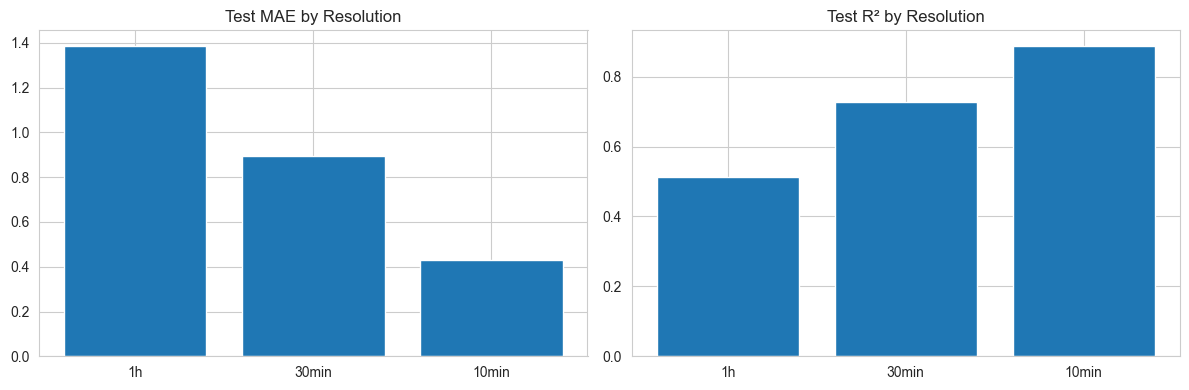

In [9]:
resolutions = ["1h", "30min", "10min"]
res_results = []

for freq in resolutions:
    X_tr, y_tr, X_te, y_te, _, _, _ = load_and_prepare(
        freq=freq, feature_level=DEFAULT_FEATURE_LEVEL, split_type=DEFAULT_SPLIT
    )
    model = lgb.LGBMRegressor(
        n_estimators=DEFAULT_N_ESTIMATORS, learning_rate=0.03, num_leaves=15,
        max_depth=6, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    )
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    res_results.append({
        "Resolution": freq,
        "Test MAE": mean_absolute_error(y_te, pred),
        "Test R²": r2_score(y_te, pred),
        "Rows (train)": len(X_tr)
    })

res_df = pd.DataFrame(res_results)
print(res_df.round(3).to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(res_df["Resolution"], res_df["Test MAE"])
ax1.set_title("Test MAE by Resolution")
ax2.bar(res_df["Resolution"], res_df["Test R²"])
ax2.set_title("Test R² by Resolution")
plt.tight_layout()
plt.show()

### 6.3 Feature Set Size

Compares performance using different numbers of features.

In [ ]:
levels = ["ultra_low", "low", "medium", "high"]
feat_results = []

for level in levels:
    X_tr, y_tr, X_te, y_te, cols, _, _ = load_and_prepare(
        feature_level=level, split_type=DEFAULT_SPLIT
    )
    model = lgb.LGBMRegressor(
        n_estimators=DEFAULT_N_ESTIMATORS, learning_rate=0.03, num_leaves=15,
        max_depth=6, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
    )
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    feat_results.append({
        "Level": level,
        "Features": len(cols),
        "Test MAE": mean_absolute_error(y_te, pred),
        "Test R²": r2_score(y_te, pred)
    })

feat_df = pd.DataFrame(feat_results)
print(feat_df.round(3).to_string(index=False))

plt.figure(figsize=(8, 4))
plt.bar(feat_df["Level"], feat_df["Test MAE"])
plt.title("Test MAE by Feature Level")
plt.ylabel("MAE")
plt.tight_layout()
plt.show()

### 6.4 Hyperparameter Tuning

Optuna is used to search for better hyperparameters.  
The scripts compare default parameters against the best parameters found.

In [2]:
# LightGBM tuning
print("=== LightGBM Tuning ===\n")
from tune_lightgbm import main as tune_lgbm
tune_lgbm()

=== LightGBM Tuning ===

Preparing data for LightGBM tuning...

Loading data | freq=10min | features=medium | split=household
Household split: 55 train homes, 13 test homes
Train rows: 50,729 | Test rows: 12,134
Train: 50,729 | Test: 12,134 | Features: 16
===== DEFAULT =====


c:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-11-24 15:41:59,961] A new study created in memory with name: no-name-26c9529b-4578-4083-b91b-9e17cbc634fe


Default          MAE:  0.495   RMSE:  1.821   MASE:  0.811

===== OPTUNA (40 trials) =====


  0%|          | 0/40 [00:00<?, ?it/s]

c:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-11-24 15:42:00,449] Trial 0 finished with value: 0.4998428659192576 and parameters: {'n_estimators': 393, 'learning_rate': 0.034267942843299294, 'num_leaves': 56, 'max_depth': 9, 'min_child_samples': 15, 'subsample': 0.670138291025014, 'colsample_bytree': 0.7606410692102392, 'reg_alpha': 0.9510958397227132, 'reg_lambda': 0.5233142910543709}. Best is trial 0 with value: 0.4998428659192576.


... (41 outputs left out)

[I 2026-11-24 15:42:08,063] Trial 37 finished with value: 0.4557349248882095 and parameters: {'n_estimators': 511, 'learning_rate': 0.026916366319487, 'num_leaves': 38, 'max_depth': 5, 'min_child_samples': 37, 'subsample': 0.9373752962897469, 'colsample_bytree': 0.9480302159479956, 'reg_alpha': 0.8884322800036172, 'reg_lambda': 2.275141218048254}. Best is trial 21 with value: 0.40225462458113825.
[I 2026-11-24 15:42:08,236] Trial 38 finished with value: 0.4516914508138273 and parameters: {'n_estimators': 539, 'learning_rate': 0.01951954511344743, 'num_leaves': 34, 'max_depth': 3, 'min_child_samples': 38, 'subsample': 0.9032999433773207, 'colsample_bytree': 0.9280760694343135, 'reg_alpha': 0.9541786881272171, 'reg_lambda': 2.2472688261207487}. Best is trial 21 with value: 0.40225462458113825.


c:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[I 2026-11-24 15:42:08,458] Trial 39 finished with value: 0.42540431798432243 and parameters: {'n_estimators': 488, 'learning_rate': 0.01893057005461715, 'num_leaves': 45, 'max_depth': 3, 'min_child_samples': 41, 'subsample': 0.9547907322693923, 'colsample_bytree': 0.9449510822323234, 'reg_alpha': 0.8760022910788016, 'reg_lambda': 2.1213750939955167}. Best is trial 21 with value: 0.40225462458113825.

===== TUNED =====
Best Test MAE: 0.4023
Best parameters:
  n_estimators: 499
  learning_rate: 0.030034238116796667
  num_leaves: 20
  max_depth: 3
  min_child_samples: 26
  subsample: 0.9588403260186881
  colsample_bytree: 0.9731703950355728
  reg_alpha: 0.9937519683349467
  reg_lambda: 2.526844082676616

===== COMPARISON =====
Default          MAE:  0.495   RMSE:  1.821   MASE:  0.811
Tuned            MAE:  0.402   RMSE:  1.750   MASE:  0.658

Saved to c:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\Project_Final_Cleaned\best_lightgbm_params.txt


c:\Users\lifra\Documents\UofT\Courses\CHE1147\CHE1147-1\.venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [ ]:
# XGBoost tuning
print("\n=== XGBoost Tuning ===\n")
from tune_xgboost import main as tune_xgb
tune_xgb()

### Tuning Notes

- Each script runs a fixed number of trials (set in `config.py` as `N_TUNING_TRIALS`).
- Best parameters are saved to:
  - `best_lightgbm_params.txt`
  - `best_xgboost_params.txt`
- Tuning can take several minutes depending on the number of trials.
- The comparison at the end shows whether tuning improved test MAE.

If you only want to run one of them, comment out the other cell.

In [ ]:
from pathlib import Path

def show_best_params(filename):
    path = Path(filename)
    if path.exists():
        print(f"\n{filename}:")
        print(path.read_text())
    else:
        print(f"{filename} not found. Run tuning first.")

show_best_params("best_lightgbm_params.txt")
show_best_params("best_xgboost_params.txt")

### 6.5 Optimization Takeaways

| Choice | Finding | Recommendation |
|--------|---------|----------------|
| Number of trees | Performance peaks around 200 trees | Use ~200 estimators |
| Time resolution | 10-min outperforms 30-min and 1-h | Prefer 10-minute data |
| Feature set | Medium set is competitive with high | Medium is a good default |
| Tuning | Modest MAE improvement | Optional but beneficial |

These checks support the default settings used in the main modeling pipeline.